# Marathi Word Recognition - OPEN VOCABULARY


In [ ]:
import os
os.environ['TF_XLA_FLAGS'] = '--tf_xla_auto_jit=0'
import tensorflow as tf, numpy as np, glob, json, random
from PIL import Image, ImageFont, ImageDraw, features
tf.config.optimizer.set_jit(False)
print('TF', tf.__version__, '| GPU', tf.config.list_physical_devices('GPU'))
print('raqm:', features.check('raqm'))
if not features.check('raqm'):
    get_ipython().system('apt-get -qq install -y libraqm-dev > /dev/null 2>&1')
    get_ipython().system('pip -q install --upgrade --force-reinstall Pillow')
    print('Installed raqm - RESTART RUNTIME then run again.')
print('XLA/JIT disabled (required for CTC)')

TF 2.20.0 | GPU [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
raqm: True
XLA/JIT disabled (required for CTC)


In [ ]:
os.makedirs('/content/fonts', exist_ok=True)
FONT_URLS = {
    'NotoSansDevanagari.ttf': 'https://github.com/google/fonts/raw/main/ofl/notosansdevanagari/NotoSansDevanagari%5Bwdth%2Cwght%5D.ttf',
    'Mukta-Regular.ttf':      'https://github.com/google/fonts/raw/main/ofl/mukta/Mukta-Regular.ttf',
    'Hind-Regular.ttf':       'https://github.com/google/fonts/raw/main/ofl/hind/Hind-Regular.ttf',
    'Kalam-Regular.ttf':      'https://github.com/google/fonts/raw/main/ofl/kalam/Kalam-Regular.ttf',
    'Baloo2.ttf':             'https://github.com/google/fonts/raw/main/ofl/baloo2/Baloo2%5Bwght%5D.ttf',
}
for name, url in FONT_URLS.items():
    dst = f'/content/fonts/{name}'
    if not os.path.exists(dst):
        get_ipython().system('curl -sL "{url}" -o "{dst}"')
font_paths = []
for p in sorted(glob.glob('/content/fonts/*.ttf')):
    try:
        ImageFont.truetype(p, 32, layout_engine=ImageFont.Layout.RAQM); font_paths.append(p)
    except Exception as e:
        print('skip', os.path.basename(p), e)
assert font_paths, 'No fonts loaded.'
print(f'{len(font_paths)} fonts ready')

5 fonts ready


In [ ]:
consonants = list('कखगघङचछजझञटठडढणतथदधनपफबभमयरलवशषसह')
matras     = ['','ा','ि','ी','ु','ू','े','ै','ो','ौ','ं','ः','्']  # '' = bare consonant

def random_word():
    n = random.randint(2, 6)
    return ''.join(random.choice(consonants) + random.choice(matras) for _ in range(n))

REAL_WORDS = [
    'नमस्कार','धन्यवाद','पाणी','शाळा','पुस्तक','मित्र','घर','गाव','मराठी','भारत',
    'सूर्य','चंद्र','पाऊस','सकाळ','रात्र','दिवाळी','दूध','चहा','शिक्षक','प्रेम',
    'मिलिंद','संगणक','विद्यालय','महाराष्ट्र','मुंबई','पुणे','आनंद','स्वप्न','भाषा','देश',
]

def sample_word():
    # 70% random (for letter-learning), 30% real (for realism)
    return random.choice(REAL_WORDS) if random.random() < 0.3 else random_word()

print('random:', [random_word() for _ in range(5)])
print('mixed :', [sample_word() for _ in range(5)])

random: ['डूङैटूलुतौछु', 'फैगैसेझीकःषो', 'बौधाषी', 'बिभंझंषंधासू', 'शेकू']
mixed : ['स्वप्न', 'फंयी', 'टचौभारेनःधू', 'पुस्तक', 'हाखाद्']


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 2350 (\N{DEVANAGARI LETTER MA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Matplotlib currently does not support Devanagari natively.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 2375 (\N{DEVANAGARI VOWEL SIGN E}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 2360 (\N{DEVANAGARI LETTER SA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 2307 (\N{DEVANAGARI SIGN VISARGA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/l

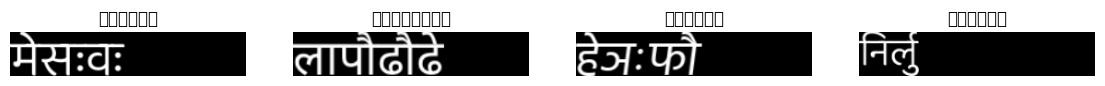

In [ ]:
IMG_H, IMG_W, CHANNELS = 48, 256, 1

def render_word(text, font_path, size=42):
    font = ImageFont.truetype(font_path, size, layout_engine=ImageFont.Layout.RAQM)
    d = ImageDraw.Draw(Image.new('L', (10, 10), 0))
    l, t, r, b = d.textbbox((0, 0), text, font=font)
    w, h, pad = max(1, r-l), max(1, b-t), 8
    c = Image.new('L', (w+2*pad, h+2*pad), 0)
    ImageDraw.Draw(c).text((pad-l, pad-t), text, fill=255, font=font)
    return np.array(c, np.float32) / 255.0

def augment(a):
    im = Image.fromarray((a*255).astype(np.uint8))
    if random.random() < 0.5:
        sh = random.uniform(-0.15, 0.15)
        im = im.transform(im.size, Image.AFFINE, (1, sh, 0, 0, 1, 0), resample=Image.BILINEAR)
    a = np.array(im, np.float32) / 255.0
    if random.random() < 0.3:
        a = np.clip(a + np.random.normal(0, 0.05, a.shape), 0, 1)
    return a

def normalize_crop(a):
    ys, xs = np.where(a > 0.3)
    if len(xs):
        a = a[ys.min():ys.max()+1, xs.min():xs.max()+1]
    h, w = a.shape
    nw = min(IMG_W, max(1, int(w * IMG_H / h)))
    im = Image.fromarray((a*255).astype(np.uint8)).resize((nw, IMG_H), Image.BILINEAR)
    a = np.array(im, np.float32) / 255.0
    out = np.zeros((IMG_H, IMG_W), np.float32); out[:, :nw] = a
    return out[..., None]

def make_sample(text, train=True):
    a = render_word(text, random.choice(font_paths), size=random.randint(36, 48) if train else 42)
    if train: a = augment(a)
    return normalize_crop(a)

import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 4, figsize=(14, 2))
for i in range(4):
    w = sample_word()
    ax[i].imshow(make_sample(w).squeeze(), cmap='gray'); ax[i].set_title(w); ax[i].axis('off')
plt.show()

In [ ]:
# build charset from many random words + all real words -> covers everything
allchars = set()
for _ in range(20000): allchars |= set(random_word())
for w in REAL_WORDS: allchars |= set(w)
charset = sorted(allchars)
char_to_idx = {c: i for i, c in enumerate(charset)}
idx_to_char = {i: c for i, c in enumerate(charset)}
NUM_CLASSES = len(charset)
MAX_LEN = 14
print(f'{NUM_CLASSES} characters in charset')
def encode(t): return [char_to_idx[c] for c in t]

49 characters in charset


In [ ]:
BATCH = 32
STEPS_PER_EPOCH = 300

def gen():
    while True:
        w = sample_word()
        y = encode(w)
        if 0 < len(y) <= MAX_LEN:
            yield make_sample(w, True), np.array(y, np.int64)

ds = tf.data.Dataset.from_generator(
    gen, output_signature=(tf.TensorSpec((IMG_H, IMG_W, CHANNELS), tf.float32),
                           tf.TensorSpec((None,), tf.int64)))
ds = ds.padded_batch(BATCH, padded_shapes=([IMG_H, IMG_W, CHANNELS], [MAX_LEN]),
                     padding_values=(0.0, tf.constant(NUM_CLASSES, tf.int64)))
ds = ds.map(lambda x, y: ({'image': x, 'label': y}, tf.zeros(tf.shape(x)[0]))).prefetch(tf.data.AUTOTUNE)

In [ ]:
from tensorflow.keras import layers, Model

def se(x, r=8):
    c = x.shape[-1]; s = layers.GlobalAveragePooling2D()(x)
    s = layers.Dense(c//r, activation='relu')(s); s = layers.Dense(c, activation='sigmoid')(s)
    return layers.Multiply()([x, layers.Reshape((1,1,c))(s)])

def spatial(x):
    avg = layers.Lambda(lambda t: tf.reduce_mean(t,-1,keepdims=True))(x)
    mx  = layers.Lambda(lambda t: tf.reduce_max(t,-1,keepdims=True))(x)
    a = layers.Conv2D(1,7,padding='same',activation='sigmoid')(layers.Concatenate()([avg,mx]))
    return layers.Multiply()([x,a])

def conv_bn(x, f, pool):
    x = layers.Conv2D(f,3,padding='same',use_bias=False)(x)
    x = layers.BatchNormalization(momentum=0.9)(x); x = layers.Activation('relu')(x)
    return layers.MaxPooling2D(pool)(x)

def pos_enc(length, depth):
    depth //= 2; pos = np.arange(length)[:,None]; d = np.arange(depth)[None,:]/depth
    ang = pos*(1/(10000**d)); return tf.cast(np.concatenate([np.sin(ang),np.cos(ang)],-1), tf.float32)

def txf(x, heads=4, ff=256, drop=0.1):
    d = x.shape[-1]; a = layers.MultiHeadAttention(heads, d//heads, dropout=drop)(x, x)
    x = layers.LayerNormalization(epsilon=1e-6)(layers.Add()([x,a]))
    fn = layers.Dense(ff, activation='relu')(x); fn = layers.Dense(d)(fn); fn = layers.Dropout(drop)(fn)
    return layers.LayerNormalization(epsilon=1e-6)(layers.Add()([x,fn]))

class CTCLayer(layers.Layer):
    def call(self, y_true, y_pred):
        b  = tf.cast(tf.shape(y_true)[0], 'int64')
        il = tf.cast(tf.shape(y_pred)[1], 'int64') * tf.ones((b,1), 'int64')
        ll = tf.cast(tf.shape(y_true)[1], 'int64') * tf.ones((b,1), 'int64')
        self.add_loss(tf.keras.backend.ctc_batch_cost(y_true, tf.cast(y_pred,'float32'), il, ll))
        return y_pred

def build_model(num_classes, training=True):
    img = layers.Input((IMG_H, IMG_W, CHANNELS), name='image')
    x = conv_bn(img, 64,  (2,2))   # 24x128
    x = conv_bn(x,   128, (2,2))   # 12x64
    x = se(x)
    x = conv_bn(x,   128, (2,1))   # 6x64
    x = conv_bn(x,   256, (2,1))   # 3x64
    x = se(x); x = spatial(x)
    x = conv_bn(x,   256, (3,1))   # 1x64
    x = layers.Reshape((64, x.shape[-1]))(x)
    x = layers.Dense(256, activation='relu')(x)
    x = x + pos_enc(64, 256)
    x = txf(x); x = txf(x)
    y = layers.Dense(num_classes+1, activation='softmax', name='logits')(x)
    if not training: return Model(img, y, name='infer')
    lab = layers.Input((None,), name='label'); return Model([img, lab], CTCLayer()(lab, y), name='train')

model = build_model(NUM_CLASSES, True)
lr = tf.keras.optimizers.schedules.CosineDecay(1e-3, decay_steps=STEPS_PER_EPOCH*30)
model.compile(optimizer=tf.keras.optimizers.Adam(lr), jit_compile=False)
print(f'{model.count_params():,} params')

2,001,029 params


In [ ]:
infer_model = build_model(NUM_CLASSES, False)

def edit_distance(a, b):
    dp = list(range(len(b)+1))
    for i, ca in enumerate(a, 1):
        prev, dp[0] = dp[0], i
        for j, cb in enumerate(b, 1):
            prev, dp[j] = dp[j], min(dp[j]+1, dp[j-1]+1, prev+(ca != cb))
    return dp[-1]

def ctc_greedy(pred):
    il = np.ones(pred.shape[0]) * pred.shape[1]
    r = tf.keras.backend.ctc_decode(pred, input_length=il, greedy=True)[0][0].numpy()
    return [''.join(idx_to_char.get(i, '') for i in seq if i != -1 and i != NUM_CLASSES) for seq in r]

def read_word(img):
    return ctc_greedy(infer_model.predict(img[None], verbose=0))[0]

In [ ]:
# words held out purely for evaluation
HELD_OUT = ['मिलिंद','संगणक','विद्यालय','महाराष्ट्र','आनंद','स्वप्न','पुस्तक','शिक्षक']

class Metrics(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        if (epoch+1) % 3 != 0: return
        infer_model.set_weights(self.model.get_weights()[:len(infer_model.get_weights())])
        X = np.stack([make_sample(w, False) for w in HELD_OUT])
        raw = ctc_greedy(infer_model.predict(X, verbose=0))
        exact = np.mean([r==w for r,w in zip(raw, HELD_OUT)])
        cer = sum(edit_distance(r,w) for r,w in zip(raw,HELD_OUT))/sum(len(w) for w in HELD_OUT)
        print(f'  [ep {epoch+1}] held-out exact-word {exact:.2f} | CER {cer:.3f}')
        print('      ' + '  '.join(f'{w}->{r}' for w,r in zip(HELD_OUT[:4], raw[:4])))

metrics_cb = Metrics()

Train


In [ ]:
history = model.fit(ds, epochs=20, steps_per_epoch=STEPS_PER_EPOCH,
                    callbacks=[metrics_cb,
                               tf.keras.callbacks.ModelCheckpoint('/content/best.weights.h5',
                                   save_weights_only=True, save_best_only=True, monitor='loss')])

Epoch 1/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 67s 168ms/step - loss: 560.8996
Epoch 2/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 52s 173ms/step - loss: 34.6524
Epoch 3/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 0s 148ms/step - loss: 21.5207  [ep 3] held-out exact-word 0.88 | CER 0.020
      मिलिंद->मिलिंद  संगणक->संगणक  विद्यालय->विद्यालय  महाराष्ट्र->महाराष्ट्र
300/300 ━━━━━━━━━━━━━━━━━━━━ 50s 166ms/step - loss: 19.2138
Epoch 4/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 46s 153ms/step - loss: 15.1266
Epoch 5/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 49s 162ms/step - loss: 13.0751
Epoch 6/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 0s 157ms/step - loss: 11.3319  [ep 6] held-out exact-word 1.00 | CER 0.000
      मिलिंद->मिलिंद  संगणक->संगणक  विद्यालय->विद्यालय  महाराष्ट्र->महाराष्ट्र
300/300 ━━━━━━━━━━━━━━━━━━━━ 48s 162ms/step - loss: 11.9705
Epoch 7/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 46s 153ms/step - loss: 11.2141
Epoch 8/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 47s 157ms/step - loss: 9.6210
Epoch 9/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 0s 148ms/step - loss: 9.20

## Test The Model

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 2306 (\N{DEVANAGARI SIGN ANUSVARA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 2342 (\N{DEVANAGARI LETTER DA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


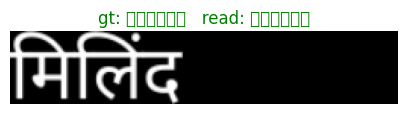

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 2327 (\N{DEVANAGARI LETTER GA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 2339 (\N{DEVANAGARI LETTER NNA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 2325 (\N{DEVANAGARI LETTER KA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


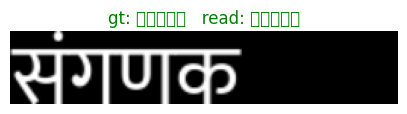

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 2355 (\N{DEVANAGARI LETTER LLA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


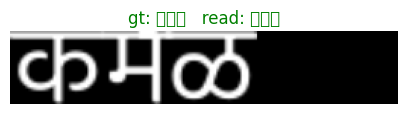

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 2368 (\N{DEVANAGARI VOWEL SIGN II}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


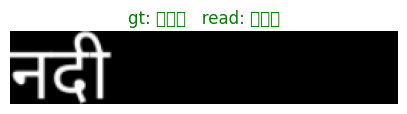

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 2332 (\N{DEVANAGARI LETTER JA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 2370 (\N{DEVANAGARI VOWEL SIGN UU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


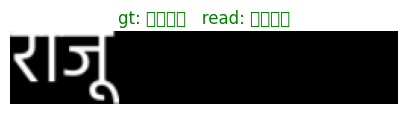

In [ ]:
infer_model.set_weights(model.get_weights()[:len(infer_model.get_weights())])

def test(word):
    im = make_sample(word, False)
    pred = read_word(im)
    ok = pred == word
    plt.figure(figsize=(5,1.6)); plt.imshow(im.squeeze(), cmap='gray'); plt.axis('off')
    plt.title(f'gt: {word}   read: {pred}', color='green' if ok else 'red'); plt.show()
    return pred

for w in ['मिलिंद','संगणक','कमळ','नदी','राजू']:   # try any Devanagari words
    test(w)

Saving WhatsApp Image 2026-08-01 at 12.19.21 PM.jpeg to WhatsApp Image 2026-08-01 at 12.19.21 PM.jpeg


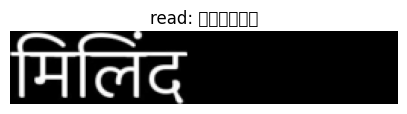

Read: मिलिंद


In [ ]:
from google.colab import files

def recognize_file(path):
    img = Image.open(path).convert('L')
    a = 1.0 - np.array(img, np.float32) / 255.0   # dark ink on light bg -> invert
    im = normalize_crop(a)
    pred = read_word(im)
    plt.figure(figsize=(5,1.6)); plt.imshow(im.squeeze(), cmap='gray'); plt.axis('off')
    plt.title(f'read: {pred}'); plt.show()
    return pred

infer_model.set_weights(model.get_weights()[:len(infer_model.get_weights())])
uploaded = files.upload()
for name in uploaded:
    print('Read:', recognize_file(name))

In [ ]:
model.save_weights('/content/marathi_openvocab.weights.h5')
with open('/content/marathi_openvocab_meta.json', 'w', encoding='utf-8') as f:
    json.dump({'char_to_idx': char_to_idx, 'max_len': MAX_LEN}, f, ensure_ascii=False)
print('saved')

saved


Available metrics: dict_keys(['loss'])
Accuracy metric not found.


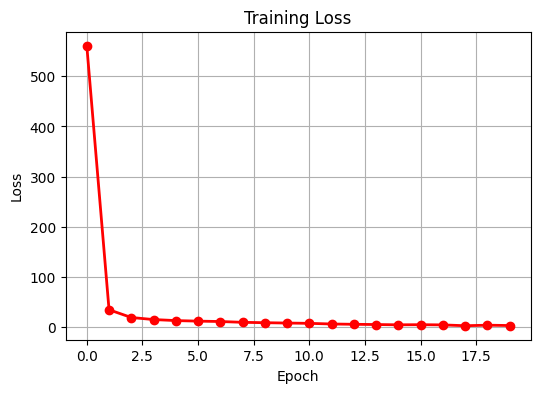

In [ ]:
import matplotlib.pyplot as plt

print("Available metrics:", history.history.keys())

# -------- Accuracy --------
acc_key = None
for k in history.history.keys():
    if "accuracy" in k.lower() or "acc" in k.lower():
        acc_key = k
        break

if acc_key:
    plt.figure(figsize=(6,4))
    plt.plot(history.history[acc_key], marker='o', linewidth=2)
    plt.title("Training Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.grid(True)
    plt.show()
else:
    print("Accuracy metric not found.")

# -------- Loss --------
plt.figure(figsize=(6,4))
plt.plot(history.history["loss"], marker='o', color='red', linewidth=2)
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)
plt.show()

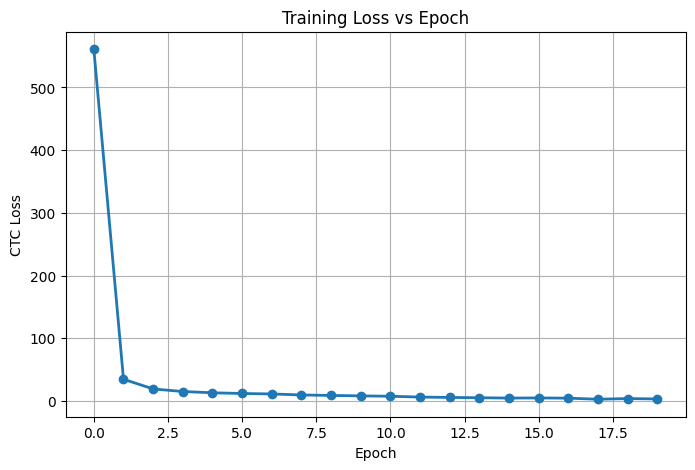

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.plot(history.history['loss'], marker='o', linewidth=2)
plt.title("Training Loss vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("CTC Loss")
plt.grid(True)
plt.show()